# 01 - Data Preprocessing and Exploratory Data Analysis

**Project:** Predicting silica impurity in the iron ore concentrate of a froth flotation plant

In this notebook we load the raw plant data, clean it, convert it from 20-second readings to
hourly values, look at the main trends and build the final table that the other notebooks use.

**Dataset:** "Quality Prediction in a Mining Process" - real data from an iron ore flotation plant
in Brazil, March to September 2017 (public domain, also on OpenML, id 43311).

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data
from src.plot_style import setup, save, COLORS
setup()

## 1. Load the raw data
The file is about 185 MB. If it is not in `data/raw/` it is downloaded automatically.

In [2]:
raw = data.load_raw()
print("Shape:", raw.shape)
raw.head()

Shape: (737453, 24)


,date,iron_feed,silica_feed,starch_flow,amina_flow,pulp_flow,pulp_pH,pulp_density,air_col1,air_col2,...,air_col7,level_col1,level_col2,level_col3,level_col4,level_col5,level_col6,level_col7,iron_conc,silica_conc
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,...,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,...,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,...,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31
3,2017-03-10 01:00:00,55.2,16.98,3047.36,568.665,397.939,10.0689,1.74,249.917,254.487,...,251.147,452.441,458.165,442.865,446.210,471.411,437.690,427.669,66.91,1.31
4,2017-03-10 01:00:00,55.2,16.98,3033.69,558.167,400.254,10.0697,1.74,250.203,252.136,...,248.928,452.441,452.900,450.523,453.670,462.598,443.682,425.679,66.91,1.31


The columns are:

| Group | Columns | Meaning |
|---|---|---|
| Feed quality | iron_feed, silica_feed | % Fe and % SiO2 in the ore going into the plant (lab) |
| Reagents | starch_flow, amina_flow | starch depresses iron oxide, amine collects silica (m3/h) |
| Pulp | pulp_flow, pulp_pH, pulp_density | flow (t/h), pH and density (kg/cm3) of the ore pulp |
| Columns | air_col1-7, level_col1-7 | air flow (Nm3/h) and froth level (mm) in the 7 flotation columns |
| Product | iron_conc, silica_conc | % Fe and % SiO2 in the final concentrate (lab, hourly) |

Target: **silica_conc** (% silica in the concentrate). Lower is better.

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 737453 entries, 0 to 737452
Data columns (total 24 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   date          737453 non-null  datetime64[us]
 1   iron_feed     737453 non-null  float64       
 2   silica_feed   737453 non-null  float64       
 3   starch_flow   737453 non-null  float64       
 4   amina_flow    737453 non-null  float64       
 5   pulp_flow     737453 non-null  float64       
 6   pulp_pH       737453 non-null  float64       
 7   pulp_density  737453 non-null  float64       
 8   air_col1      737453 non-null  float64       
 9   air_col2      737453 non-null  float64       
 10  air_col3      737453 non-null  float64       
 11  air_col4      737453 non-null  float64       
 12  air_col5      737453 non-null  float64       
 13  air_col6      737453 non-null  float64       
 14  air_col7      737453 non-null  float64       
 15  level_col1    737453 non-nul

## 2. Data quality checks

In [4]:
print("Missing values in any column:", raw.isna().sum().sum())
print("Duplicate rows:", raw.duplicated().sum(), "(repeated 20 s readings - they disappear in the hourly average)")
print("Date range:", raw.date.min(), "to", raw.date.max())
print("Unique hours:", raw.date.nunique())

Missing values in any column: 0


Duplicate rows: 1171 (repeated 20 s readings - they disappear in the hourly average)
Date range: 2017-03-10 01:00:00 to 2017-09-09 23:00:00
Unique hours: 4097


**Sampling rate.** The timestamp only has the hour, so every hour has many rows. Let us count them.

In [5]:
rows_per_hour = raw.groupby("date").size()
rows_per_hour.value_counts().head()

180    4095
174       1
179       1
Name: count, dtype: int64

Almost every hour has 180 rows, i.e. one reading every 20 seconds (3600 / 20 = 180).
But the lab values (feed and concentrate quality) are measured only once an hour.
Check how many distinct values each column takes inside one hour:

In [6]:
distinct_in_hour = raw.groupby("date").nunique().max().sort_values()
distinct_in_hour

iron_feed         1
silica_feed       1
starch_flow     180
amina_flow      180
pulp_flow       180
pulp_pH         180
pulp_density    180
air_col1        180
air_col2        180
air_col3        180
air_col4        180
air_col5        180
air_col6        180
air_col7        180
level_col1      180
level_col2      180
level_col3      180
level_col4      180
level_col5      180
level_col6      180
level_col7      180
iron_conc       180
silica_conc     180
dtype: int64

- `iron_feed` and `silica_feed` are constant inside an hour (lab values).
- `silica_conc` changes inside some hours - these are hours where the values were filled in
  (interpolated) in the original file. It is not a real 20-second measurement.

Because the target is really an **hourly** lab value, we average every hour into one row.
This also removes a lot of sensor noise.

**Gaps in time.** Check if any hours are missing.

In [7]:
hourly_all = raw.groupby("date").mean()
full_range = pd.date_range(hourly_all.index.min(), hourly_all.index.max(), freq="h")
missing = full_range.difference(hourly_all.index)
print("Missing hours:", len(missing))
print("From", missing.min(), "to", missing.max())

Missing hours: 318
From 2017-03-16 06:00:00 to 2017-03-29 11:00:00


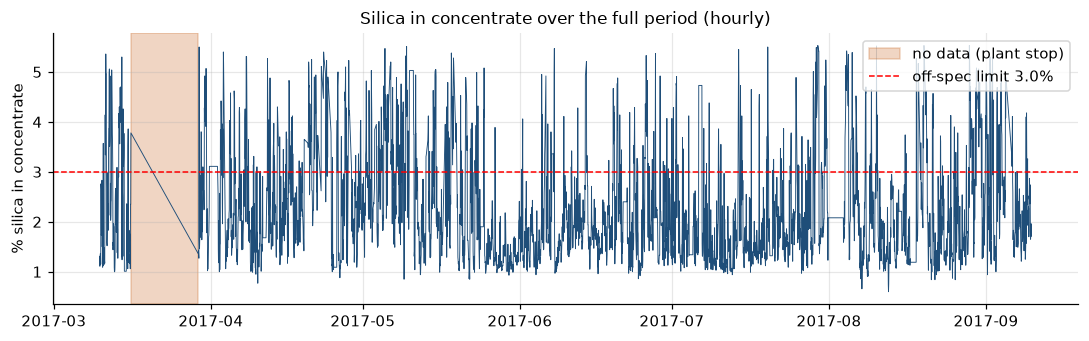

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(hourly_all.index, hourly_all["silica_conc"], lw=0.6, color=COLORS["main"])
ax.axvspan(missing.min(), missing.max(), color=COLORS["accent"], alpha=0.25, label="no data (plant stop)")
ax.axhline(data.OFF_SPEC_LIMIT, color="red", ls="--", lw=1, label=f"off-spec limit {data.OFF_SPEC_LIMIT}%")
ax.set_ylabel("% silica in concentrate")
ax.set_title("Silica in concentrate over the full period (hourly)")
ax.legend(loc="upper right")
save(fig, "fig01_silica_timeseries")
plt.show()

There is a 13-day stoppage in March (318 missing hours). We only keep data **after** this gap
(from 29 March 2017, 12:00), so the series is continuous. This keeps about 96 % of the hours.

## 3. Outliers
We use the IQR rule (below Q1 - 1.5 IQR or above Q3 + 1.5 IQR) on the hourly data.

In [9]:
h = hourly_all[hourly_all.index >= data.START]
q1, q3 = h.quantile(0.25), h.quantile(0.75)
iqr = q3 - q1
outlier_frac = ((h < q1 - 1.5 * iqr) | (h > q3 + 1.5 * iqr)).mean().sort_values(ascending=False)
(outlier_frac * 100).round(1).head(10)

air_col6        34.7
air_col7        33.8
air_col4        33.8
air_col5        31.8
pulp_flow       29.8
pulp_density     6.5
level_col7       2.0
pulp_pH          1.8
amina_flow       1.4
silica_conc      0.8
dtype: float64

The IQR rule flags a lot of points in `air_col4`-`air_col7` and `pulp_flow`. These variables sit
almost constant most of the time (for example air in columns 4 and 5 stays very close to 300 Nm3/h),
so the IQR is very narrow and even small normal changes get flagged. Columns 1-3, 6 and 7 also have
periods where the air was turned down to about 200 Nm3/h - a real operating change, not a sensor error.
All values are inside physically normal plant ranges, so we **keep** them. Deleting them would remove
exactly the situations the model needs to learn from.

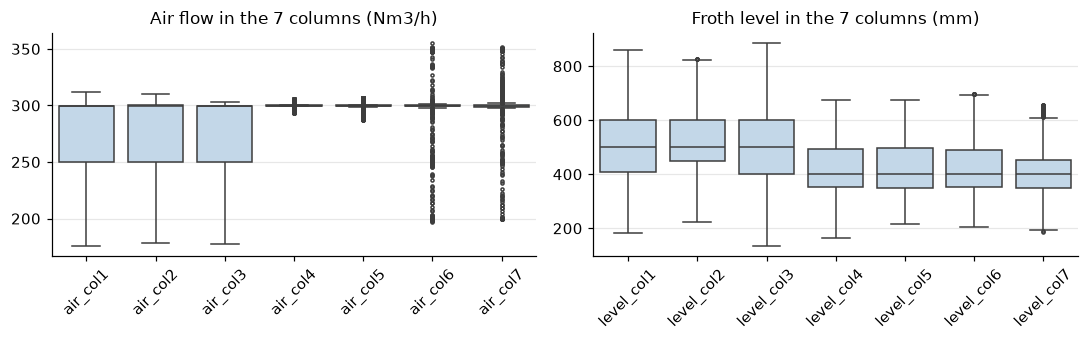

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
sns.boxplot(data=h[[f"air_col{i}" for i in range(1, 8)]], ax=axes[0], color=COLORS["light"], fliersize=2)
axes[0].set_title("Air flow in the 7 columns (Nm3/h)")
axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=h[[f"level_col{i}" for i in range(1, 8)]], ax=axes[1], color=COLORS["light"], fliersize=2)
axes[1].set_title("Froth level in the 7 columns (mm)")
axes[1].tick_params(axis="x", rotation=45)
save(fig, "fig02_column_boxplots")
plt.show()

## 4. Build the hourly modelling table

Steps (done in `src/data.py -> make_hourly`):
1. average the 20-second readings of each hour,
2. keep the hours after the March stoppage,
3. add the **last lab report** as two features: `silica_prev_hr` and `iron_prev_hr`,
4. add a 0/1 label `off_spec` = 1 when silica > 3.0 %.

**Why the previous-hour lab values?** In the plant, the lab result for hour *t-1* is already known
when we want to predict hour *t*. So it is a fair input. Using `iron_conc` of the **same** hour is
not fair - it comes from the same lab sample as the silica we are trying to predict (see below).

In [11]:
hourly = data.make_hourly(raw)
os.makedirs(os.path.dirname(data.HOURLY_PATH), exist_ok=True)
hourly.to_csv(data.HOURLY_PATH)
print("Hourly table:", hourly.shape)
print("Saved to", os.path.relpath(data.HOURLY_PATH, data.ROOT))
hourly[data.FEATURES + [data.TARGET, "off_spec"]].describe().T.round(2)

Hourly table: (3947, 26)
Saved to data\processed\flotation_hourly.csv


,count,mean,std,min,25%,50%,75%,max
iron_feed,3947.0,56.22,5.23,42.74,52.61,55.94,59.72,65.78
silica_feed,3947.0,14.77,6.89,1.31,8.80,14.20,20.14,33.40
starch_flow,3947.0,2847.47,948.61,54.60,2146.30,2880.47,3514.84,6270.16
amina_flow,3947.0,488.75,83.76,242.93,436.49,502.74,550.16,736.98
pulp_flow,3947.0,397.47,8.49,376.84,398.77,399.84,400.59,418.07
pulp_pH,3947.0,9.77,0.38,8.75,9.54,9.80,10.03,10.81
pulp_density,3947.0,1.68,0.06,1.52,1.65,1.69,1.72,1.82
air_col1,3947.0,281.31,29.34,175.89,250.11,299.85,299.96,312.30
air_col2,3947.0,278.20,29.46,178.19,250.12,299.60,299.99,309.89
air_col3,3947.0,282.27,28.22,177.20,250.11,299.89,299.95,302.78


## 5. Exploratory analysis
### 5.1 Distribution of the target

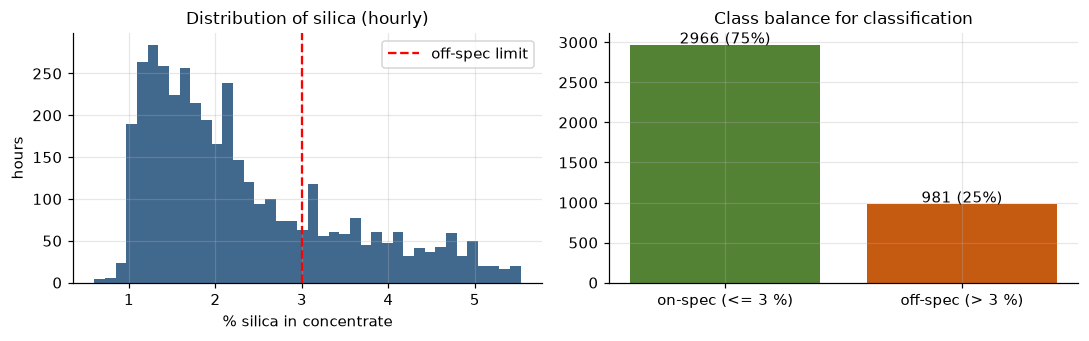

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(hourly[data.TARGET], bins=40, color=COLORS["main"], alpha=0.85)
axes[0].axvline(data.OFF_SPEC_LIMIT, color="red", ls="--", label="off-spec limit")
axes[0].set_xlabel("% silica in concentrate"); axes[0].set_ylabel("hours")
axes[0].set_title("Distribution of silica (hourly)"); axes[0].legend()
counts = hourly["off_spec"].value_counts().sort_index()
axes[1].bar(["on-spec (<= 3 %)", "off-spec (> 3 %)"], counts.values, color=[COLORS["good"], COLORS["accent"]])
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 20, f"{v} ({v / counts.sum():.0%})", ha="center")
axes[1].set_title("Class balance for classification")
save(fig, "fig03_target_distribution")
plt.show()

Silica is right-skewed: most hours are between 1 and 3 %, with a tail up to 5.5 %.
About a quarter of the hours are off-spec, so the classes are imbalanced (roughly 3 : 1).

### 5.2 Correlation with silica

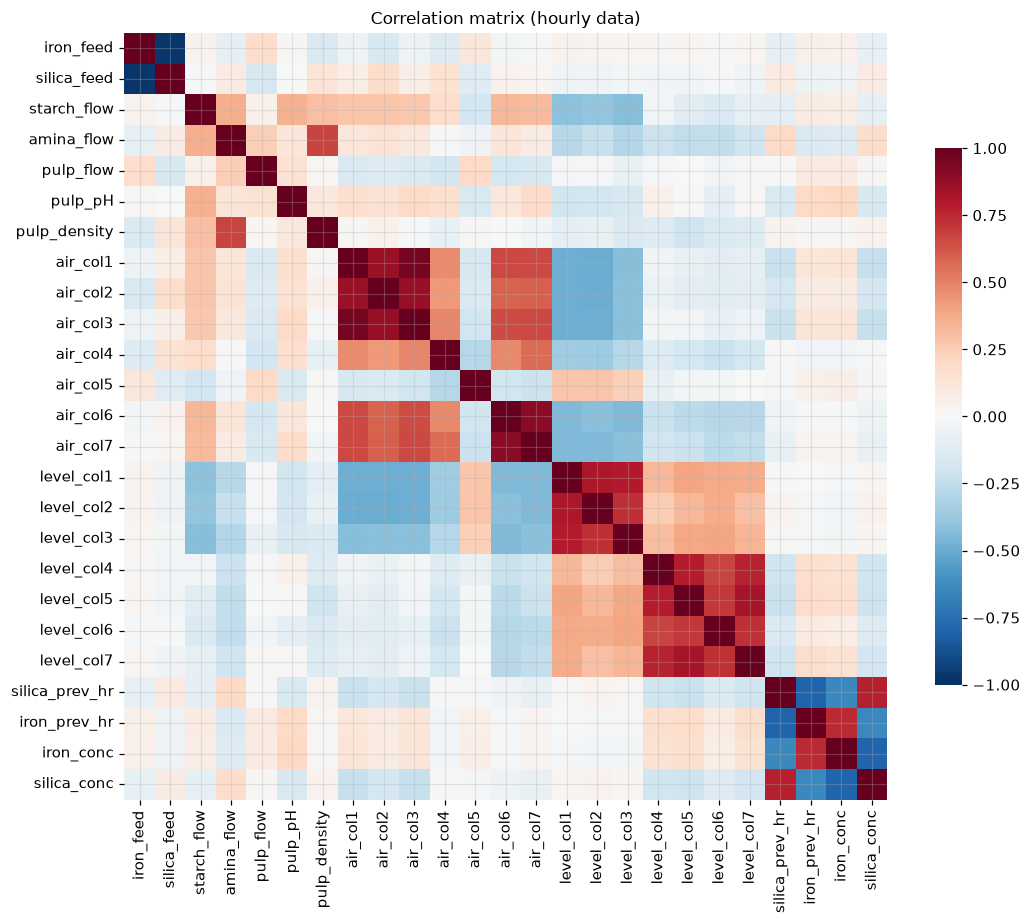

In [13]:
corr = hourly[data.PROCESS_VARS + ["silica_prev_hr", "iron_prev_hr", "iron_conc", data.TARGET]].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7},
            xticklabels=True, yticklabels=True)
ax.set_title("Correlation matrix (hourly data)")
save(fig, "fig04_correlation_heatmap")
plt.show()

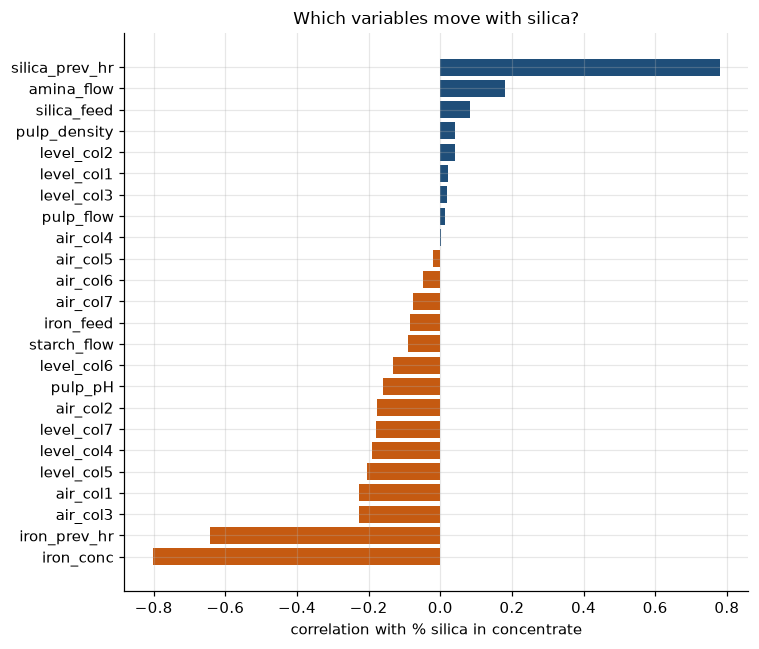

iron_conc        -0.803
iron_prev_hr     -0.642
air_col3         -0.227
air_col1         -0.227
level_col5       -0.204
level_col4       -0.190
level_col7       -0.180
air_col2         -0.175
pulp_pH          -0.161
level_col6       -0.131
starch_flow      -0.090
iron_feed        -0.085
air_col7         -0.075
air_col6         -0.048
air_col5         -0.019
air_col4          0.002
pulp_flow         0.012
level_col3        0.019
level_col1        0.022
level_col2        0.040
pulp_density      0.040
silica_feed       0.082
amina_flow        0.180
silica_prev_hr    0.780
Name: silica_conc, dtype: float64

In [14]:
target_corr = corr[data.TARGET].drop(data.TARGET).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
colors = [COLORS["accent"] if v < 0 else COLORS["main"] for v in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=colors)
ax.set_xlabel("correlation with % silica in concentrate")
ax.set_title("Which variables move with silica?")
save(fig, "fig05_target_correlation")
plt.show()
target_corr.round(3)

Observations:
- `iron_conc` (same hour) has a very strong negative correlation (about -0.8) with silica.
  The concentrate is mostly Fe oxide + silica, so when one goes up the other goes down.
- `silica_prev_hr` is strongly positive - silica changes slowly, so the last lab value is a good guide.
- All the process variables have weak correlations (below 0.25 in size). The strongest are the air
  flows in columns 1-3 (more air -> less silica) and `amina_flow` (positive, because operators add
  more amine when the silica is already high - a control action, not a cause).
- The air flows of columns 1, 2, 3 are strongly correlated with each other, and so are 6 and 7.
  Same for the levels. This multicollinearity is a reason to try Ridge/Lasso and PCA later.

### 5.3 The leakage problem with `iron_conc`

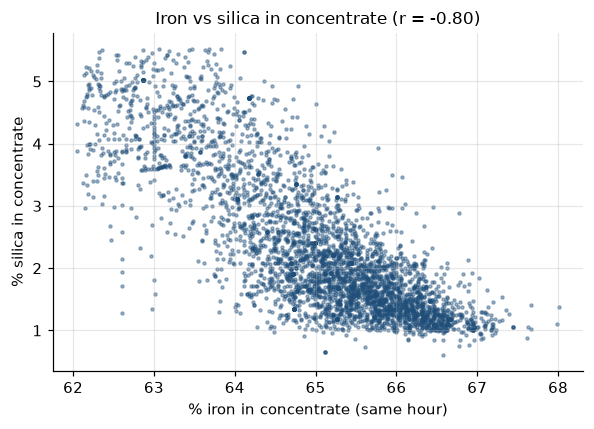

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(hourly["iron_conc"], hourly[data.TARGET], s=4, alpha=0.4, color=COLORS["main"])
ax.set_xlabel("% iron in concentrate (same hour)")
ax.set_ylabel("% silica in concentrate")
ax.set_title(f"Iron vs silica in concentrate (r = {hourly['iron_conc'].corr(hourly[data.TARGET]):.2f})")
save(fig, "fig06_iron_vs_silica")
plt.show()

Both numbers come from **the same lab analysis**, at the same time. If we had the iron result we
would also already have the silica result, so using `iron_conc` as an input would be cheating
(data leakage). We drop it and only use the previous hour's lab values.

### 5.4 Train / test split
This is time-series data, so neighbouring hours are very similar. If we split randomly, the test
set would contain hours sitting right next to training hours and the score would look much better
than reality. So we split **by time**: first 70 % for training, last 30 % for testing.

Train: 2017-03-29 13:00:00 to 2017-07-22 14:00:00  (2762 hours)
Test : 2017-07-22 15:00:00 to 2017-09-09 23:00:00  (1185 hours)
Off-spec share - train 25.3%, test 23.9%


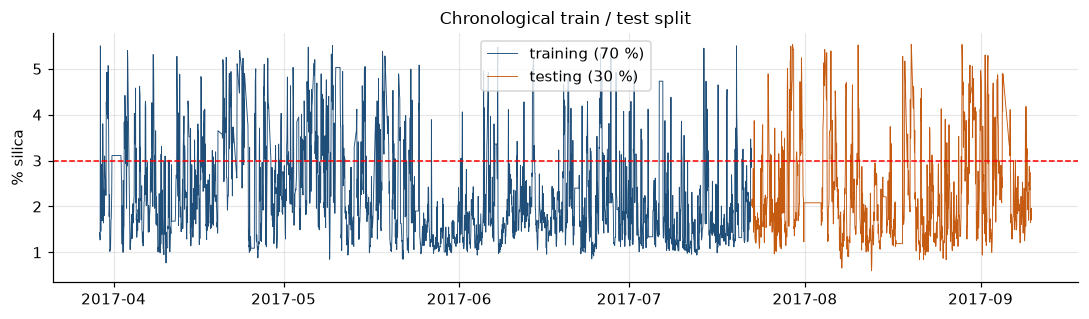

In [16]:
train, test = data.time_split(hourly)
print(f"Train: {train.index.min()} to {train.index.max()}  ({len(train)} hours)")
print(f"Test : {test.index.min()} to {test.index.max()}  ({len(test)} hours)")
print(f"Off-spec share - train {train.off_spec.mean():.1%}, test {test.off_spec.mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(train.index, train[data.TARGET], lw=0.6, color=COLORS["main"], label="training (70 %)")
ax.plot(test.index, test[data.TARGET], lw=0.6, color=COLORS["accent"], label="testing (30 %)")
ax.axhline(data.OFF_SPEC_LIMIT, color="red", ls="--", lw=1)
ax.set_ylabel("% silica"); ax.set_title("Chronological train / test split"); ax.legend()
save(fig, "fig07_train_test_split")
plt.show()

### 5.5 Feature scaling
The inputs have very different units and ranges (starch flow is around 3000, pH around 10,
density around 1.7). Distance-based and gradient-based methods (KNN, SVM, gradient descent,
neural networks, PCA, K-means) need scaled inputs. We use **standardisation**
z = (x - mean) / std, fitted on the training data only and then applied to the test data.

In [17]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(train[data.FEATURES])
print("Before scaling (train):")
print(train[["starch_flow", "pulp_pH", "pulp_density"]].agg(["mean", "std"]).round(2))
z = pd.DataFrame(scaler.transform(train[data.FEATURES]), columns=data.FEATURES)
print("\nAfter scaling (train):")
print(z[["starch_flow", "pulp_pH", "pulp_density"]].agg(["mean", "std"]).round(2))

Before scaling (train):
      starch_flow  pulp_pH  pulp_density
mean      2746.13     9.79          1.68
std        977.69     0.33          0.07

After scaling (train):
      starch_flow  pulp_pH  pulp_density
mean         -0.0      0.0           0.0
std           1.0      1.0           1.0


## Summary
- 737,453 raw rows (20 s) -> 3,947 clean hourly rows from 29 Mar to 9 Sep 2017.
- 21 process variables + 2 previous-hour lab values = **23 input features**.
- Regression target: % silica. Classification target: off-spec (> 3 %), about 25 % of hours.
- `iron_conc` of the same hour is removed (leakage). Split is chronological 70/30.
- Saved table: `data/processed/flotation_hourly.csv` (used by notebooks 02-04).